# Preparing for OCR

The ROI-Extraction of the region containing the digits is now complete. The next step is to apply Optical Character Recognition (OCR) to extract the digits from the identified region.

Test-image is `data/2026-11-15_ocr/010_roi.jpg`

![](data/2026-11-15_ocr/010_roi.jpg)

Possible Problems: 

- The ROI-Extraction is not perfect, so a bigger ROI must be used. So the "Opening" in the meter-dial produces a rectangle-shape
- The digits-area is skewed
- There is little contrast between digits and backgorund.
- And of course: The half , when the roles are rotating.

A preprocessing shall refine the image to improve the OCR-accuracy. The preprocessing should include:

- Deskewing
- Contrast-enhancement
- Binarization

In [1]:
import math

import cv2
import numpy as np
from matplotlib import pyplot as plt


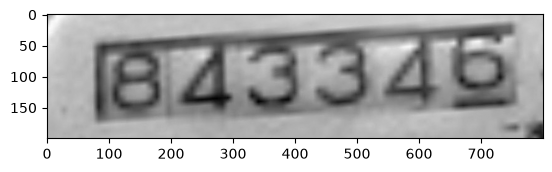

In [2]:
# --- usage on the test image ---
rv = cv2.imread('data/2026-11-15_ocr/010_roi.jpg', cv2.IMREAD_GRAYSCALE)
assert rv is not None, 'image not found'
img: np.ndarray = rv

plt.imshow(img, cmap='gray'); plt.show()

## Contrast enhancement

max, min of contrast enhanced image: 255, 2


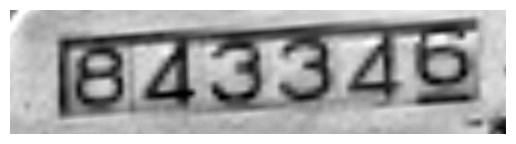

In [3]:
def contrast_normalization(img: np.ndarray) -> np.ndarray:
    sigma = max(1.0, min(img.shape[:2]) * 0.02)
    blurred = cv2.GaussianBlur(img, (0, 0), sigma)
    blurred_min = np.min(blurred)
    blurred_max = np.max(blurred)
    normalized_float = (img.astype(np.float32) - blurred_min) / (blurred_max - blurred_min)
    normalized = np.clip(normalized_float * 255, 0, 255).astype(np.uint8)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(normalized)
    return enhanced

contrast_enhanced = contrast_normalization(img)

print(f"max, min of contrast enhanced image: {np.max(contrast_enhanced)}, {np.min(contrast_enhanced)}")

plt.imshow(contrast_enhanced, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

## Deskewing

estimated skew: -3.00 deg


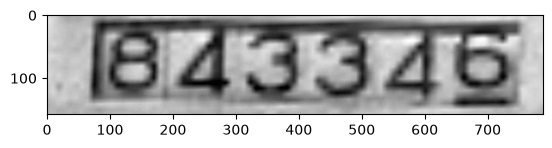

In [4]:
def estimate_skew_angle(binary_ink, angle_range=(-10, 10), step=0.1):
    """Estimate skew by projection profile: the correct angle maximizes
    the variance of the per-row ink counts (sharp text lines)."""
    h, w = binary_ink.shape
    best_angle, best_score = 0.0, -1.0
    for a in np.arange(angle_range[0], angle_range[1] + step, step):
        M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
        rot = cv2.warpAffine(binary_ink, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
        score = rot.sum(axis=1).astype(np.float64).var()
        if score > best_score:
            best_angle, best_score = a, score
    return best_angle

def deskew(img, angle, crop=True):
    """Rotate img by angle (getRotationMatrix2D convention) and, if crop=True,
    cut away the empty border areas introduced by the rotation."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    border = 255 if img.ndim == 2 else (255, 255, 255)
    rot = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderValue=border)
    if not crop:
        return rot
    # Largest axis-aligned rectangle fully inside the rotated image,
    # centered at the image center (valid while |angle| < atan(h/w) etc.):
    a = math.radians(abs(angle))
    sin_a, cos_a = math.sin(a), math.cos(a)
    cw = w * cos_a - h * sin_a
    ch = h * cos_a - w * sin_a
    x0 = round((w - cw) / 2)
    y0 = round((h - ch) / 2)
    return rot[y0:y0 + round(ch), x0:x0 + round(cw)]

angle = estimate_skew_angle(np.bitwise_not(contrast_enhanced))
print(f'estimated skew: {angle:.2f} deg')
deskewed = deskew(contrast_enhanced, angle)
plt.imshow(deskewed, cmap='gray'); plt.show()

## Binarization

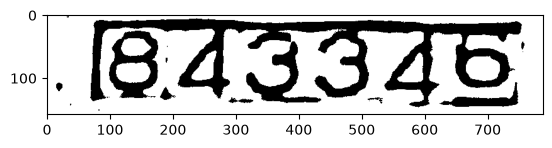

In [5]:
deskewed_tresh = cv2.adaptiveThreshold(deskewed, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 75, 15)   # ink = 255
plt.imshow(deskewed_tresh, cmap='gray'); plt.show()

In [6]:
import pytesseract

config = "--oem 3 --psm 7 -c tessedit_char_whitelist=0123456789"
text = pytesseract.image_to_string(deskewed_tresh, config=config)
print(text.strip())

843345


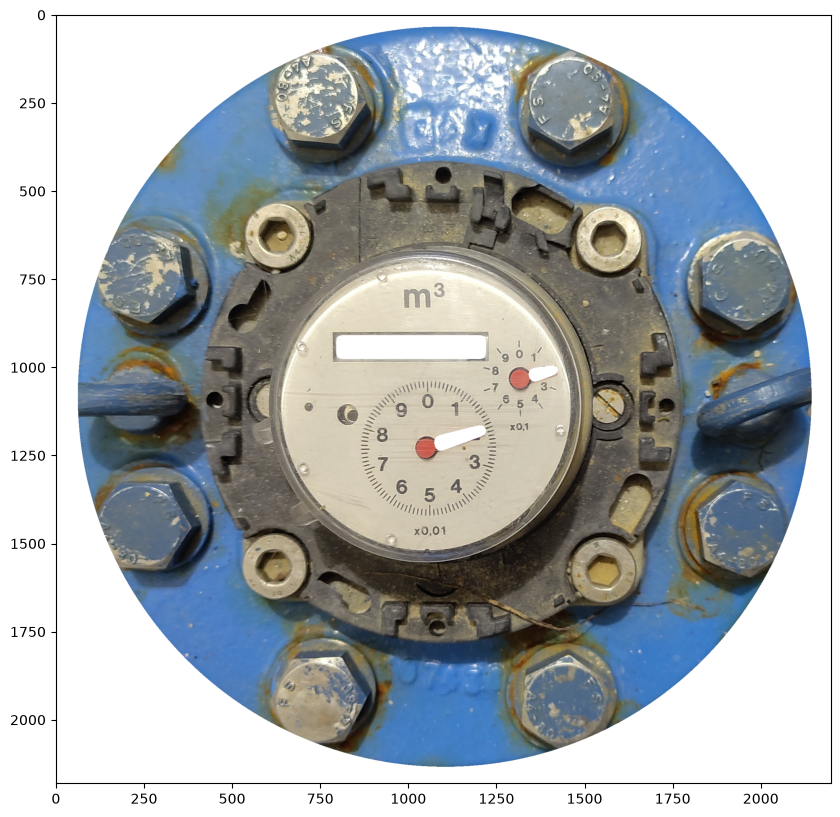

In [11]:
img = cv2.imread("../water_meter/preselect-image.png", cv2.IMREAD_UNCHANGED)
img[:, :, 3] = np.where(img[:, :, 3] >= 128, 255, 0).astype(np.uint8)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)); plt.show()